### Анализ датасета Used Cars

Скачиваем данные:

In [2]:
import pandas as pd
data = pd.read_csv('used_cars.csv')

# EDA:

In [10]:
print('Размер датасета:', data.shape)

Размер датасета: (4009, 12)


In [13]:
data.head()

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$10,300"
1,Hyundai,Palisade SEL,2021,"34,742 mi.",Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,"$38,005"
2,Lexus,RX 350 RX 350,2022,"22,372 mi.",Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,"$54,598"
3,INFINITI,Q50 Hybrid Sport,2015,"88,900 mi.",Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,"$15,500"
4,Audi,Q3 45 S line Premium Plus,2021,"9,835 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,"$34,999"


In [12]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 4009 entries, 0 to 4008
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   brand         4009 non-null   str  
 1   model         4009 non-null   str  
 2   model_year    4009 non-null   int64
 3   milage        4009 non-null   str  
 4   fuel_type     3839 non-null   str  
 5   engine        4009 non-null   str  
 6   transmission  4009 non-null   str  
 7   ext_col       4009 non-null   str  
 8   int_col       4009 non-null   str  
 9   accident      3896 non-null   str  
 10  clean_title   3413 non-null   str  
 11  price         4009 non-null   str  
dtypes: int64(1), str(11)
memory usage: 376.0 KB


In [18]:
overview = pd.DataFrame({"Тип": data.dtypes,
                         "Пропуски": data.isna().sum(),
                         "Пропуски, %": (data.isna().mean() * 100).round(1),
                         "Уникальные значения": data.nunique()
})
print(overview)

                Тип  Пропуски  Пропуски, %  Уникальные значения
brand           str         0          0.0                   57
model           str         0          0.0                 1898
model_year    int64         0          0.0                   34
milage          str         0          0.0                 2818
fuel_type       str       170          4.2                    7
engine          str         0          0.0                 1146
transmission    str         0          0.0                   62
ext_col         str         0          0.0                  319
int_col         str         0          0.0                  156
accident        str       113          2.8                    2
clean_title     str       596         14.9                    1
price           str         0          0.0                 1569


In [19]:
print("Полных дубликатов:", data.duplicated().sum())

Полных дубликатов: 0


In [25]:
data_raw = data.copy()
data["price"] = pd.to_numeric(data["price"].astype("string").str.replace("$", "", regex=False).str.replace(",", "", regex = False), errors ="raise")
data["milage"] = pd.to_numeric(data["milage"].astype("string")
    .str.replace("mi.", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip(),
    errors="raise"
)

In [27]:
print(data[["price", "milage", "model_year"]].head())

   price  milage  model_year
0  10300   51000        2013
1  38005   34742        2021
2  54598   22372        2022
3  15500   88900        2015
4  34999    9835        2021


In [28]:
print("Цена ≤ 0:", (data["price"] <= 0).sum())
print("Пробег < 0:", (data["milage"] < 0).sum())
print("Пропуски после преобразования:")
print(data[["price", "milage"]].isna().sum())

Цена ≤ 0: 0
Пробег < 0: 0
Пропуски после преобразования:
price     0
milage    0
dtype: int64


In [31]:
from sklearn.model_selection import train_test_split

train_data, test_data = train_test_split(data, test_size = 0.2, random_state = 42)
print("Обучающая выборка:", train_data.shape)
print("Тестовая выборка:", test_data.shape)

Обучающая выборка: (3207, 12)
Тестовая выборка: (802, 12)


In [35]:
import matplotlib.pyplot as plt

columns = ["price", "milage", "model_year"]
labels = ["Цена, $", "Пробег, мили", "Модельный год"]

print(train_data[columns].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]).round(1))

          price    milage  model_year
count    3207.0    3207.0      3207.0
mean    43125.8   64942.2      2015.6
std     51204.5   52433.5         6.0
min      2000.0     100.0      1974.0
25%     17050.0   23319.5      2012.0
50%     31300.0   53500.0      2017.0
75%     49999.0   93985.5      2020.0
95%    109970.0  165317.8      2023.0
99%    259470.0  224940.0      2023.0
max    749950.0  405000.0      2024.0


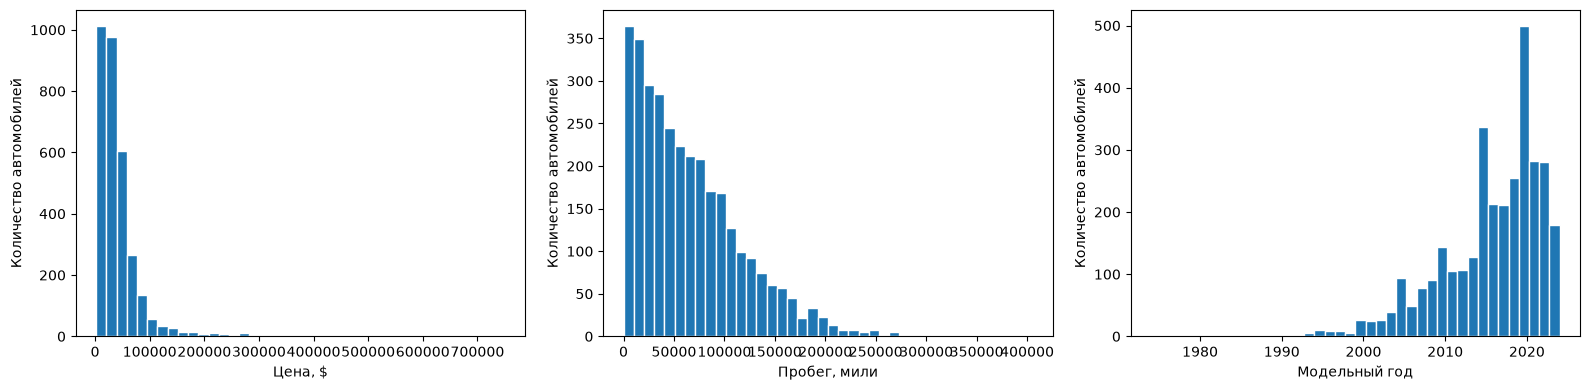

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, column, label in zip(axes, columns, labels):
    ax.hist(train_data[column], bins=40, edgecolor="white")
    ax.set_xlabel(label)
    ax.set_ylabel("Количество автомобилей")

plt.tight_layout()
plt.show()

Возьмем 99% перцентиль чтобы отрезать правый хвост у распределения.

Так же возьмем логарифм от стоимости чтобы сделать распределение более симметричным.

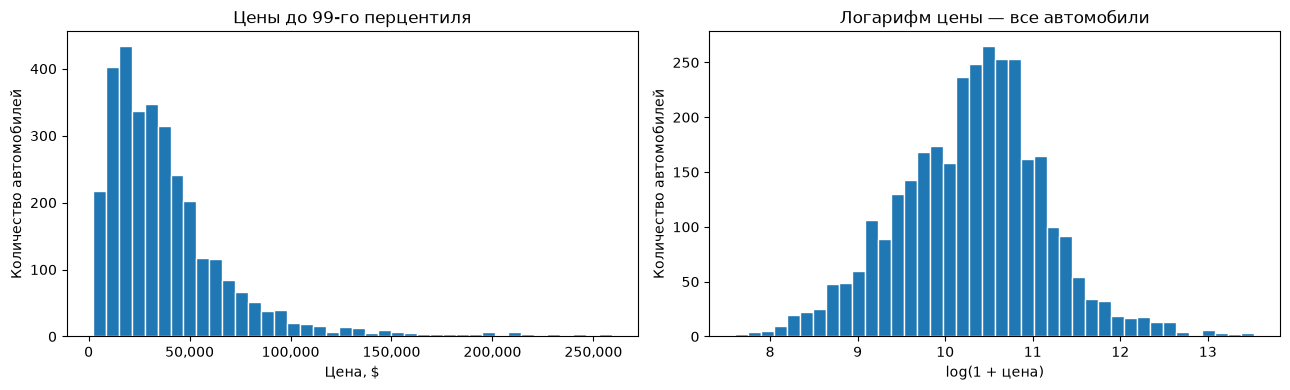

In [42]:
from matplotlib.ticker import StrMethodFormatter
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

price_p99 = train_data["price"].quantile(0.99)

axes[0].hist(train_data.loc[train_data["price"] <= price_p99, "price"], bins=40, edgecolor="white")
axes[0].set_title("Цены до 99-го перцентиля")
axes[0].set_xlabel("Цена, $")
axes[0].xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))

axes[1].hist(np.log1p(train_data["price"]), bins=40, edgecolor="white")
axes[1].set_title("Логарифм цены — все автомобили")
axes[1].set_xlabel("log(1 + цена)")

for ax in axes:
    ax.set_ylabel("Количество автомобилей")

plt.tight_layout()
plt.show()

Нам не удалось избавиться от тяжелого хвоста распределения цены, но зато распределение цены после логарифмирования стало заметно симметричнее. 

Теперь давайте проверим гипотезу 1 и 2. 

### 1. Чем новее модельный год, тем выше цена. Корреляция Спирмена положительна.
### 2. Чем больше пробег, тем ниже цена. Корреляция Спирмена отрицательная. 

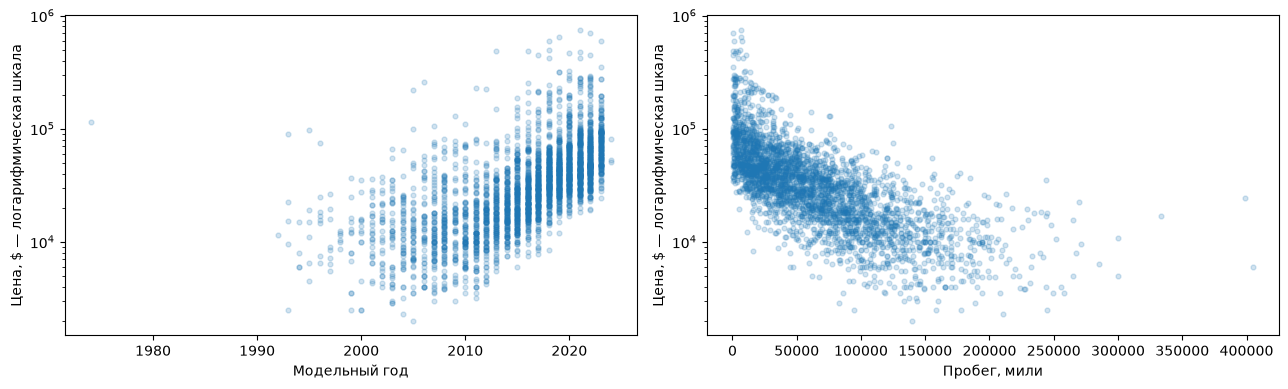

Корреляция Спирмена с ценой:
model_year    0.701
milage       -0.759
Name: price, dtype: float64


In [43]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, column, label in zip(axes, ["model_year", "milage"], ["Модельный год", "Пробег, мили"]):
    ax.scatter(
        train_data[column],
        train_data["price"],
        alpha=0.2,
        s=12
    )
    ax.set_yscale("log")
    ax.set_xlabel(label)
    ax.set_ylabel("Цена, $ — логарифмическая шкала")

plt.tight_layout()
plt.show()

spearman = train_data[["price", "model_year", "milage"]].corr(
    method="spearman"
)

print("Корреляция Спирмена с ценой:")
print(spearman["price"].drop("price").round(3))

Обе гипотезы подтвердились на обучающей выборке. Коэф. Корреляции спирмена будем обозначать $\rho_s$.

1. Цена/год модельного ряда имеет положительную корреляцию - гипотеза 1. $\rho_s = 0.701$

2. Цена/пробег имеют отрицательную корреляцию - гипотеза 2. $\rho_s = -0.759$

Проверим насколько связаны пробег и модельный год.

In [45]:
print(train_data[["price", "model_year", "milage"]].corr(method="spearman").round(3))

            price  model_year  milage
price       1.000       0.701  -0.759
model_year  0.701       1.000  -0.728
milage     -0.759      -0.728   1.000


Их связь имеет отрицательную корреляцию спирмена $\rho_s = -0.728$

Перейдем к проверке гипотезы 3:

In [47]:
brand_stats = (
    train_data.groupby("brand")
    .agg(
        count=("price", "size"),
        median_price=("price", "median")
    )
    .sort_values("count", ascending=False)
)

print(brand_stats.head(15))

               count  median_price
brand                             
BMW              310       32542.0
Ford             310       32150.0
Mercedes-Benz    263       38880.0
Chevrolet        231       32000.0
Porsche          157       66500.0
Toyota           147       29950.0
Audi             146       35499.5
Lexus            136       30709.5
Jeep             120       31165.5
Land             102       44998.0
Nissan            92       18249.0
Cadillac          90       24847.5
RAM               76       43375.0
GMC               72       31450.0
Dodge             71       22500.0


Видим, что медианная цена заметно сильно различается внутри разных брендов, так например Ниссан имеет медиану - 18249, а Land - 44998, разница больше чем в два раза, такое нельзя списать на совпадение.

Проверим разброс цен внутри самых популярных марок

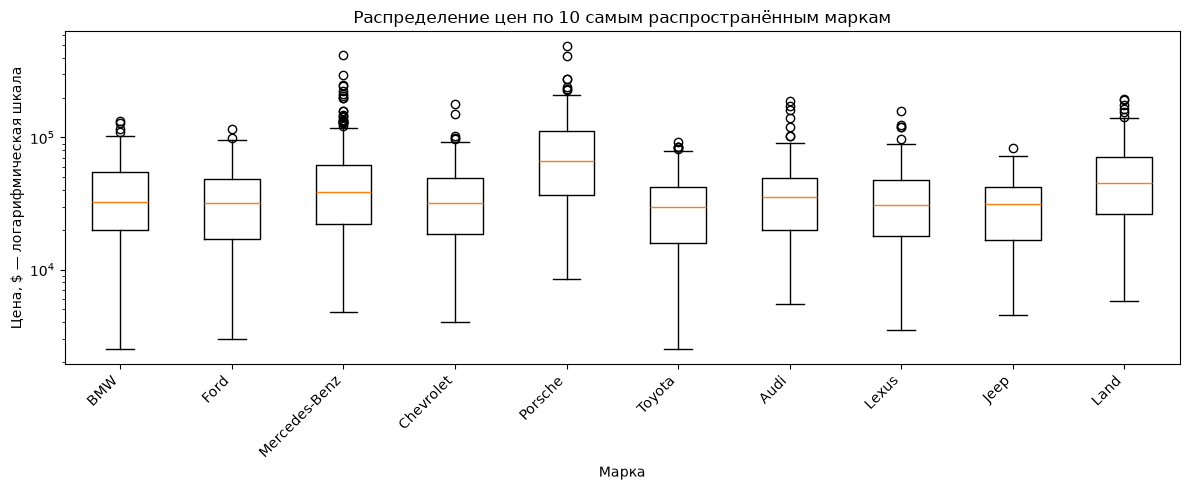

In [48]:
top_brands = brand_stats.head(10).index

prices_by_brand = [
    train_data.loc[train_data["brand"] == brand, "price"]
    for brand in top_brands
]

fig, ax = plt.subplots(figsize=(12, 5))

ax.boxplot(prices_by_brand)
ax.set_xticks(range(1, len(top_brands) + 1))
ax.set_xticklabels(top_brands, rotation=45, ha="right")
ax.set_yscale("log")

ax.set_xlabel("Марка")
ax.set_ylabel("Цена, $ — логарифмическая шкала")
ax.set_title("Распределение цен по 10 самым распространённым маркам")

plt.tight_layout()
plt.show()

Видно, что у большинства брендов стоимости значительно пересекаются, однако Porsche имеет среднюю намного выше и почти полностью лежит выше. Так же Mercedes-Benz, Porsche, Audi, Land Rover имеют наблюдений выше усов.

In [52]:
features = ["model_year", "milage", "brand"]

X_train = train_data[features].copy()
y_train = train_data["price"].copy()

Обучим лин.рег на model + year+ brand через One-hot-encoding

In [54]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge

numeric_features = ["model_year", "milage"]
categorical_features = ["brand"]

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

ridge_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Ridge(alpha=1.0, solver="lsqr"))
])

In [55]:
from sklearn.model_selection import KFold, cross_val_score

cv = KFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(
    ridge_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_mean_absolute_error"
)

mae_scores = -scores

print("MAE на каждом разбиении:", mae_scores.round(2))
print(f"Средняя MAE: ${mae_scores.mean():,.2f}")
print(f"Стандартное отклонение MAE: ${mae_scores.std():,.2f}")

MAE на каждом разбиении: [16370.45 18118.71 19818.8  17333.17 15971.06]
Средняя MAE: $17,522.44
Стандартное отклонение MAE: $1,371.02


Проверим лучше ли эта модель Baseline который предсказывает медаинную цену.

In [56]:
from sklearn.dummy import DummyRegressor

baseline = DummyRegressor(strategy="median")

baseline_mae = -cross_val_score(
    baseline,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_mean_absolute_error"
)

comparison = pd.DataFrame({
    "Медианный прогноз": baseline_mae,
    "Ridge": mae_scores
})

comparison.index = range(1, 6)
comparison.index.name = "Разбиение"

display(comparison.round(2))

improvement = (
    1 - mae_scores.mean() / baseline_mae.mean()
) * 100

print(f"Средняя MAE медианного прогноза: ${baseline_mae.mean():,.2f}")
print(f"Снижение MAE у Ridge: {improvement:.1f}%")

,Медианный прогноз,Ridge
Разбиение,,
1,23431.59,16370.45
2,27262.23,18118.71
3,29445.71,19818.80
4,25681.80,17333.17
5,22384.93,15971.06


Средняя MAE медианного прогноза: $25,641.25
Снижение MAE у Ridge: 31.7%


Наша модель лучше Baseline медианной, MAE снизилось на 31.7% Теперь проверим уменьшает ли MAE добавленеи марки автомобиля.

In [57]:
ridge_without_brand = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=1.0, solver="lsqr"))
])

mae_without_brand = -cross_val_score(
    ridge_without_brand,
    X_train[["model_year", "milage"]],
    y_train,
    cv=cv,
    scoring="neg_mean_absolute_error"
)

brand_comparison = pd.DataFrame({
    "Без марки": mae_without_brand,
    "С маркой": mae_scores,
    "Снижение MAE, $": mae_without_brand - mae_scores
})

brand_comparison.index = range(1, 6)
brand_comparison.index.name = "Разбиение"

display(brand_comparison.round(2))

brand_improvement = (
    1 - mae_scores.mean() / mae_without_brand.mean()
) * 100

print(f"Средняя MAE без марки: ${mae_without_brand.mean():,.2f}")
print(f"Средняя MAE с маркой: ${mae_scores.mean():,.2f}")
print(f"Снижение MAE после добавления марки: {brand_improvement:.1f}%")

,Без марки,С маркой,"Снижение MAE, $"
Разбиение,,,
1,21206.99,16370.45,4836.54
2,24632.46,18118.71,6513.75
3,24940.73,19818.80,5121.93
4,23442.32,17333.17,6109.15
5,19972.49,15971.06,4001.43


Средняя MAE без марки: $22,839.00
Средняя MAE с маркой: $17,522.44
Снижение MAE после добавления марки: 23.3%


Да, добавление марки снижает MAE - гипотеза 3 подтвердилась. MAE снизилиась на 23.3%

Теперь проверим влияет ли добавление log к цене.

In [58]:
import numpy as np
from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor

ridge_log = TransformedTargetRegressor(
    regressor=clone(ridge_pipeline),
    func=np.log1p,
    inverse_func=np.expm1
)

mae_log = -cross_val_score(
    ridge_log,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_mean_absolute_error"
)

log_comparison = pd.DataFrame({
    "Ridge: исходная цена": mae_scores,
    "Ridge: логарифм цены": mae_log,
    "Снижение MAE, $": mae_scores - mae_log
})

display(log_comparison.round(2))

print(f"Средняя MAE исходной модели: ${mae_scores.mean():,.2f}")
print(f"Средняя MAE модели с логарифмом: ${mae_log.mean():,.2f}")

,Ridge: исходная цена,Ridge: логарифм цены,"Снижение MAE, $"
0,16370.45,13052.29,3318.15
1,18118.71,14959.67,3159.04
2,19818.80,16218.93,3599.87
3,17333.17,14072.15,3261.02
4,15971.06,11833.83,4137.23


Средняя MAE исходной модели: $17,522.44
Средняя MAE модели с логарифмом: $14,027.37


Да, среднее MAE модели с логарифмом снизилось.

Теперь проверим гипотезу 5 — ограничение глубины дерева снижает переобучение.

In [59]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import cross_validate

depth_results = []

for depth in [3, 5, 7, 10, 15, None]:
    tree_pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", DecisionTreeRegressor(
            max_depth=depth,
            random_state=42
        ))
    ])

    result = cross_validate(
        tree_pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_mean_absolute_error",
        return_train_score=True
    )

    depth_results.append({
        "Глубина": str(depth) if depth is not None else "Без ограничения",
        "MAE train": -result["train_score"].mean(),
        "MAE validation": -result["test_score"].mean()
    })

depth_comparison = pd.DataFrame(depth_results)
display(depth_comparison.round(2))

,Глубина,MAE train,MAE validation
0,3,18566.43,18979.66
1,5,15840.41,17324.95
2,7,13608.78,16178.03
3,10,11038.99,16236.67
4,15,6624.86,16230.18
5,Без ограничения,52.72,18098.77


Гипотеза 5 верна, на дереве без ограничений MAE минимально на обучающей, однако оно сильно хуже дерева с ограничением на валидационной выборке.

Дерево с глубиной 7 самое лучшее, так как деревья с глубиной 7-10-15 дают примерно равный результат на тестовой, но дерево с глубиной 7 не так сильно переобучено.

Лучший из проверенных вариантов — Ridge на логарифме цены. Но мы использовали alpha = 1, теперь давайте подберем этот гиперпараметр чтобы улучшить точность.

In [61]:
from sklearn.model_selection import GridSearchCV

ridge_search = GridSearchCV(
    estimator=clone(ridge_log),
    param_grid={
        "regressor__model__alpha": [0.01, 0.1, 1, 10, 100, 1000]
    },
    scoring="neg_mean_absolute_error",
    cv=cv,
    n_jobs=1
)

ridge_search.fit(X_train, y_train)

alpha_results = pd.DataFrame({
    "alpha": ridge_search.cv_results_[
        "param_regressor__model__alpha"
    ],
    "Средняя MAE": -ridge_search.cv_results_["mean_test_score"],
    "Стандартное отклонение": ridge_search.cv_results_["std_test_score"]
})

display(alpha_results.round(2))

print("Лучшие параметры:", ridge_search.best_params_)
print(f"Лучшая MAE на CV: ${-ridge_search.best_score_:,.2f}")

,alpha,Средняя MAE,Стандартное отклонение
0,0.01,13949.33,1386.87
1,0.10,13953.86,1401.92
2,1.00,14027.37,1512.38
3,10.00,15422.65,1921.16
4,100.00,17342.97,2201.88
5,1000.00,18753.14,2275.51


Лучшие параметры: {'regressor__model__alpha': 0.01}
Лучшая MAE на CV: $13,949.33


Лучшее значение MAE дает alpha = 0.01

Теперь проведем отбор признаков.

In [62]:
from sklearn.feature_selection import SelectPercentile, f_regression

selection_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("selection", SelectPercentile(score_func=f_regression)),
    ("model", Ridge(alpha=0.01, solver="lsqr"))
])

selection_log = TransformedTargetRegressor(
    regressor=selection_pipeline,
    func=np.log1p,
    inverse_func=np.expm1
)

selection_search = GridSearchCV(
    estimator=selection_log,
    param_grid={
        "regressor__selection__percentile": [50, 75, 100]
    },
    scoring="neg_mean_absolute_error",
    cv=cv,
    n_jobs=1
)

selection_search.fit(X_train, y_train)

selection_results = pd.DataFrame({
    "Оставлено признаков, %": selection_search.cv_results_[
        "param_regressor__selection__percentile"
    ],
    "Средняя MAE": -selection_search.cv_results_["mean_test_score"]
})

display(selection_results.round(2))

,"Оставлено признаков, %",Средняя MAE
0,50,14383.08
1,75,14103.33
2,100,13949.33


Отбор признаков не улучшил модель. Фиксируем её как есть. Ridge на логарифме цены, alpha=0.01, признаки — год, пробег и марка, без отбора. Теперь проверяем её.


In [63]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

final_model = ridge_search.best_estimator_

X_test = test_data[["model_year", "milage", "brand"]].copy()
y_test = test_data["price"]

predictions = final_model.predict(X_test)

test_mae = mean_absolute_error(y_test, predictions)
test_rmse = np.sqrt(mean_squared_error(y_test, predictions))
test_r2 = r2_score(y_test, predictions)

print(f"Test MAE: ${test_mae:,.2f}")
print(f"Test RMSE: ${test_rmse:,.2f}")
print(f"Test R²: {test_r2:.3f}")

Test MAE: $21,908.60
Test RMSE: $138,580.35
Test R²: 0.060


In [64]:
errors = X_test.copy()
errors["actual_price"] = y_test
errors["predicted_price"] = predictions
errors["absolute_error"] = (
    errors["actual_price"] - errors["predicted_price"]
).abs()
errors["squared_error"] = (
    errors["actual_price"] - errors["predicted_price"]
) ** 2

display(
    errors.nlargest(10, "absolute_error")[
        ["brand", "model_year", "milage",
         "actual_price", "predicted_price", "absolute_error"]
    ].round(0)
)

top5_share = (
    errors.nlargest(5, "squared_error")["squared_error"].sum()
    / errors["squared_error"].sum()
)

print(f"Доля 5 крупнейших ошибок в сумме квадратов ошибок: {top5_share:.1%}")
print(f"Медианная абсолютная ошибка: ${errors['absolute_error'].median():,.2f}")

,brand,model_year,milage,actual_price,predicted_price,absolute_error
693,Maserati,2005,32000,2954083,23108.0,2930975.0
229,Bugatti,2011,6330,1950995,35695.0,1915300.0
3046,Porsche,2005,4400,1599000,51332.0,1547668.0
1061,Dodge,2017,1389,489995,47978.0,442017.0
203,Ford,2005,1897,429998,26022.0,403976.0
1575,Mercedes-Benz,2022,4760,229000,72638.0,156362.0
1694,Porsche,2023,265,279950,130428.0,149522.0
93,Aston,2021,2165,279950,132596.0,147354.0
1811,Lamborghini,2016,3254,399900,278644.0,121256.0
354,Land,2023,324,199998,80276.0,119722.0


Доля 5 крупнейших ошибок в сумме квадратов ошибок: 97.5%
Медианная абсолютная ошибка: $7,553.48


Видно, что нашу модель ломают ровно 5 машин.

In [65]:
display(
    errors.nlargest(5, "absolute_error")[
        ["brand", "model_year", "milage",
         "actual_price", "predicted_price", "absolute_error"]
    ].round(0)
)

,brand,model_year,milage,actual_price,predicted_price,absolute_error
693,Maserati,2005,32000,2954083,23108.0,2930975.0
229,Bugatti,2011,6330,1950995,35695.0,1915300.0
3046,Porsche,2005,4400,1599000,51332.0,1547668.0
1061,Dodge,2017,1389,489995,47978.0,442017.0
203,Ford,2005,1897,429998,26022.0,403976.0


Отсюда можно сделать вывод, что учитывать марку, пробег и год - недостаточно. Также обучение на логарифме цены уменьшает вклад дорогих автомобилей, из-за этого модель делает плохие прогнозы на модели из верхнего ценового сегмента.

Проверим обучалась ли наша модель вообще на этих моделях.

In [67]:
top_errors = errors.nlargest(5, "absolute_error").copy()

top_errors["model"] = test_data.loc[top_errors.index, "model"]
top_errors["brand_count_train"] = (
    top_errors["brand"]
    .map(train_data["brand"].value_counts())
    .fillna(0)
    .astype(int)
)

display(
    top_errors[
        ["brand", "model", "brand_count_train",
         "actual_price", "predicted_price", "absolute_error"]
    ].round(0)
)

,brand,model,brand_count_train,actual_price,predicted_price,absolute_error
693,Maserati,Quattroporte Base,26,2954083,23108.0,2930975.0
229,Bugatti,Veyron 16.4 Grand Sport,0,1950995,35695.0,1915300.0
3046,Porsche,Carrera GT Base,157,1599000,51332.0,1547668.0
1061,Dodge,Viper GTC,71,489995,47978.0,442017.0
203,Ford,GT,310,429998,26022.0,403976.0


Видим, что Буггати вообще не было в обучении, также мы плохо различали модели внутри брендов, в случае с Dodge, Ford, Posche это приводит к колоссальным ошибкам.